In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

## 5.1

1. E(K), let's assume that we have $\lambda=\langle k\rangle$
   $$
   \begin{align*}
   \mathbb{E}(K)
   &=\sum_{k=0}^{\infty} k\,e^{-\lambda}\frac{\lambda^k}{k!}
   = e^{-\lambda}\sum_{k=1}^{\infty} k\frac{\lambda^k}{k!} \\
   &= e^{-\lambda}\sum_{k=1}^{\infty}\lambda\frac{\lambda^{k-1}}{(k-1)!}
   = e^{-\lambda}\lambda\sum_{j=0}^{\infty}\frac{\lambda^j}{j!}
   = \lambda.
   \end{align*}
   $$
   $$
   \begin{align*}
   \mathbb{E}(K^2)
   &=\sum_{k=0}^{\infty} k^2\,e^{-\lambda}\frac{\lambda^k}{k!}
   = e^{-\lambda}\sum_{k=0}^{\infty}\big(k(k-1)+k\big)\frac{\lambda^k}{k!} \\
   &= e^{-\lambda}\sum_{k=2}^{\infty}k(k-1)\frac{\lambda^k}{k!}
   $$

- e^{-\lambda}\sum*{k=1}^{\infty}k\frac{\lambda^k}{k!} \\
  &= e^{-\lambda}\lambda^2\sum*{m=0}^{\infty}\frac{\lambda^m}{m!} + \lambda
  = \lambda^2 + \lambda.
  \end{align\*}
  $$
  $$
  \operatorname{Var}(K)=\mathbb{E}(K^2)-[\mathbb{E}(K)]^2
  = (\lambda^2+\lambda)-\lambda^2 = \lambda.
  $$
  We can see that $\frac{k\lambda^k}{k!} = \frac{\lambda* k * \lambda^{k-1}}{k (k-1)!}$
  $= \lambda \frac{\lambda^{k-1}}{(k - 1)!}$
  $$


## 5.2

Clusetring coeficient $\langle C\rangle = p$. Check the above analytical result by simulation.


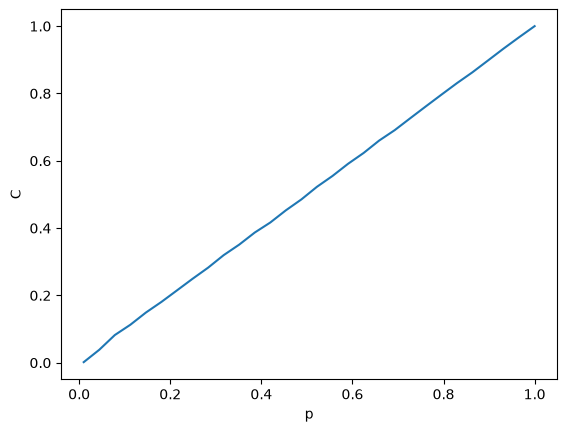

In [2]:
p = np.linspace(0.01, 1, 30)
c = [
    np.mean([nx.average_clustering(nx.gnp_random_graph(100, x)) for _ in range(20)])
    for x in p
]

plt.plot(p, c)
plt.xlabel("p")
plt.ylabel("C")
plt.show()

## 5.3

Generate and draw a graph consisting of 4 community each with N =20 nodes and the probability of connection within the
community higher than between them. Draw the result. How it depends on the parameter values?


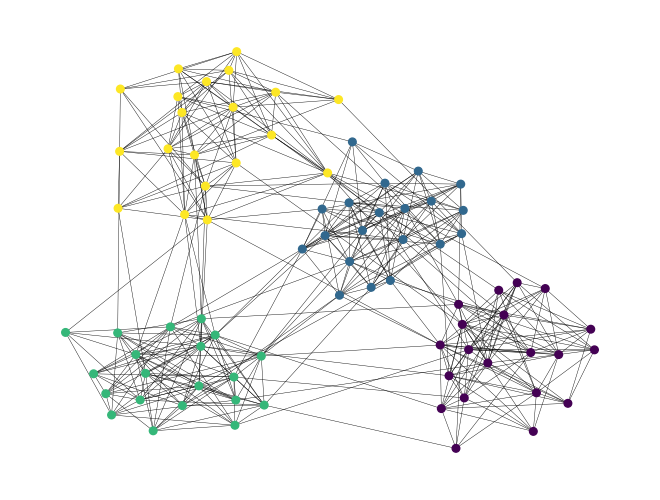

In [3]:
p_in, p_out = 0.5, 0.02
p = [[p_in if i == j else p_out for j in range(4)] for i in range(4)]
G = nx.stochastic_block_model([20] * 4, p)

nx.draw(G, node_color=[i // 20 for i in G], node_size=30, width=0.3)
plt.show()

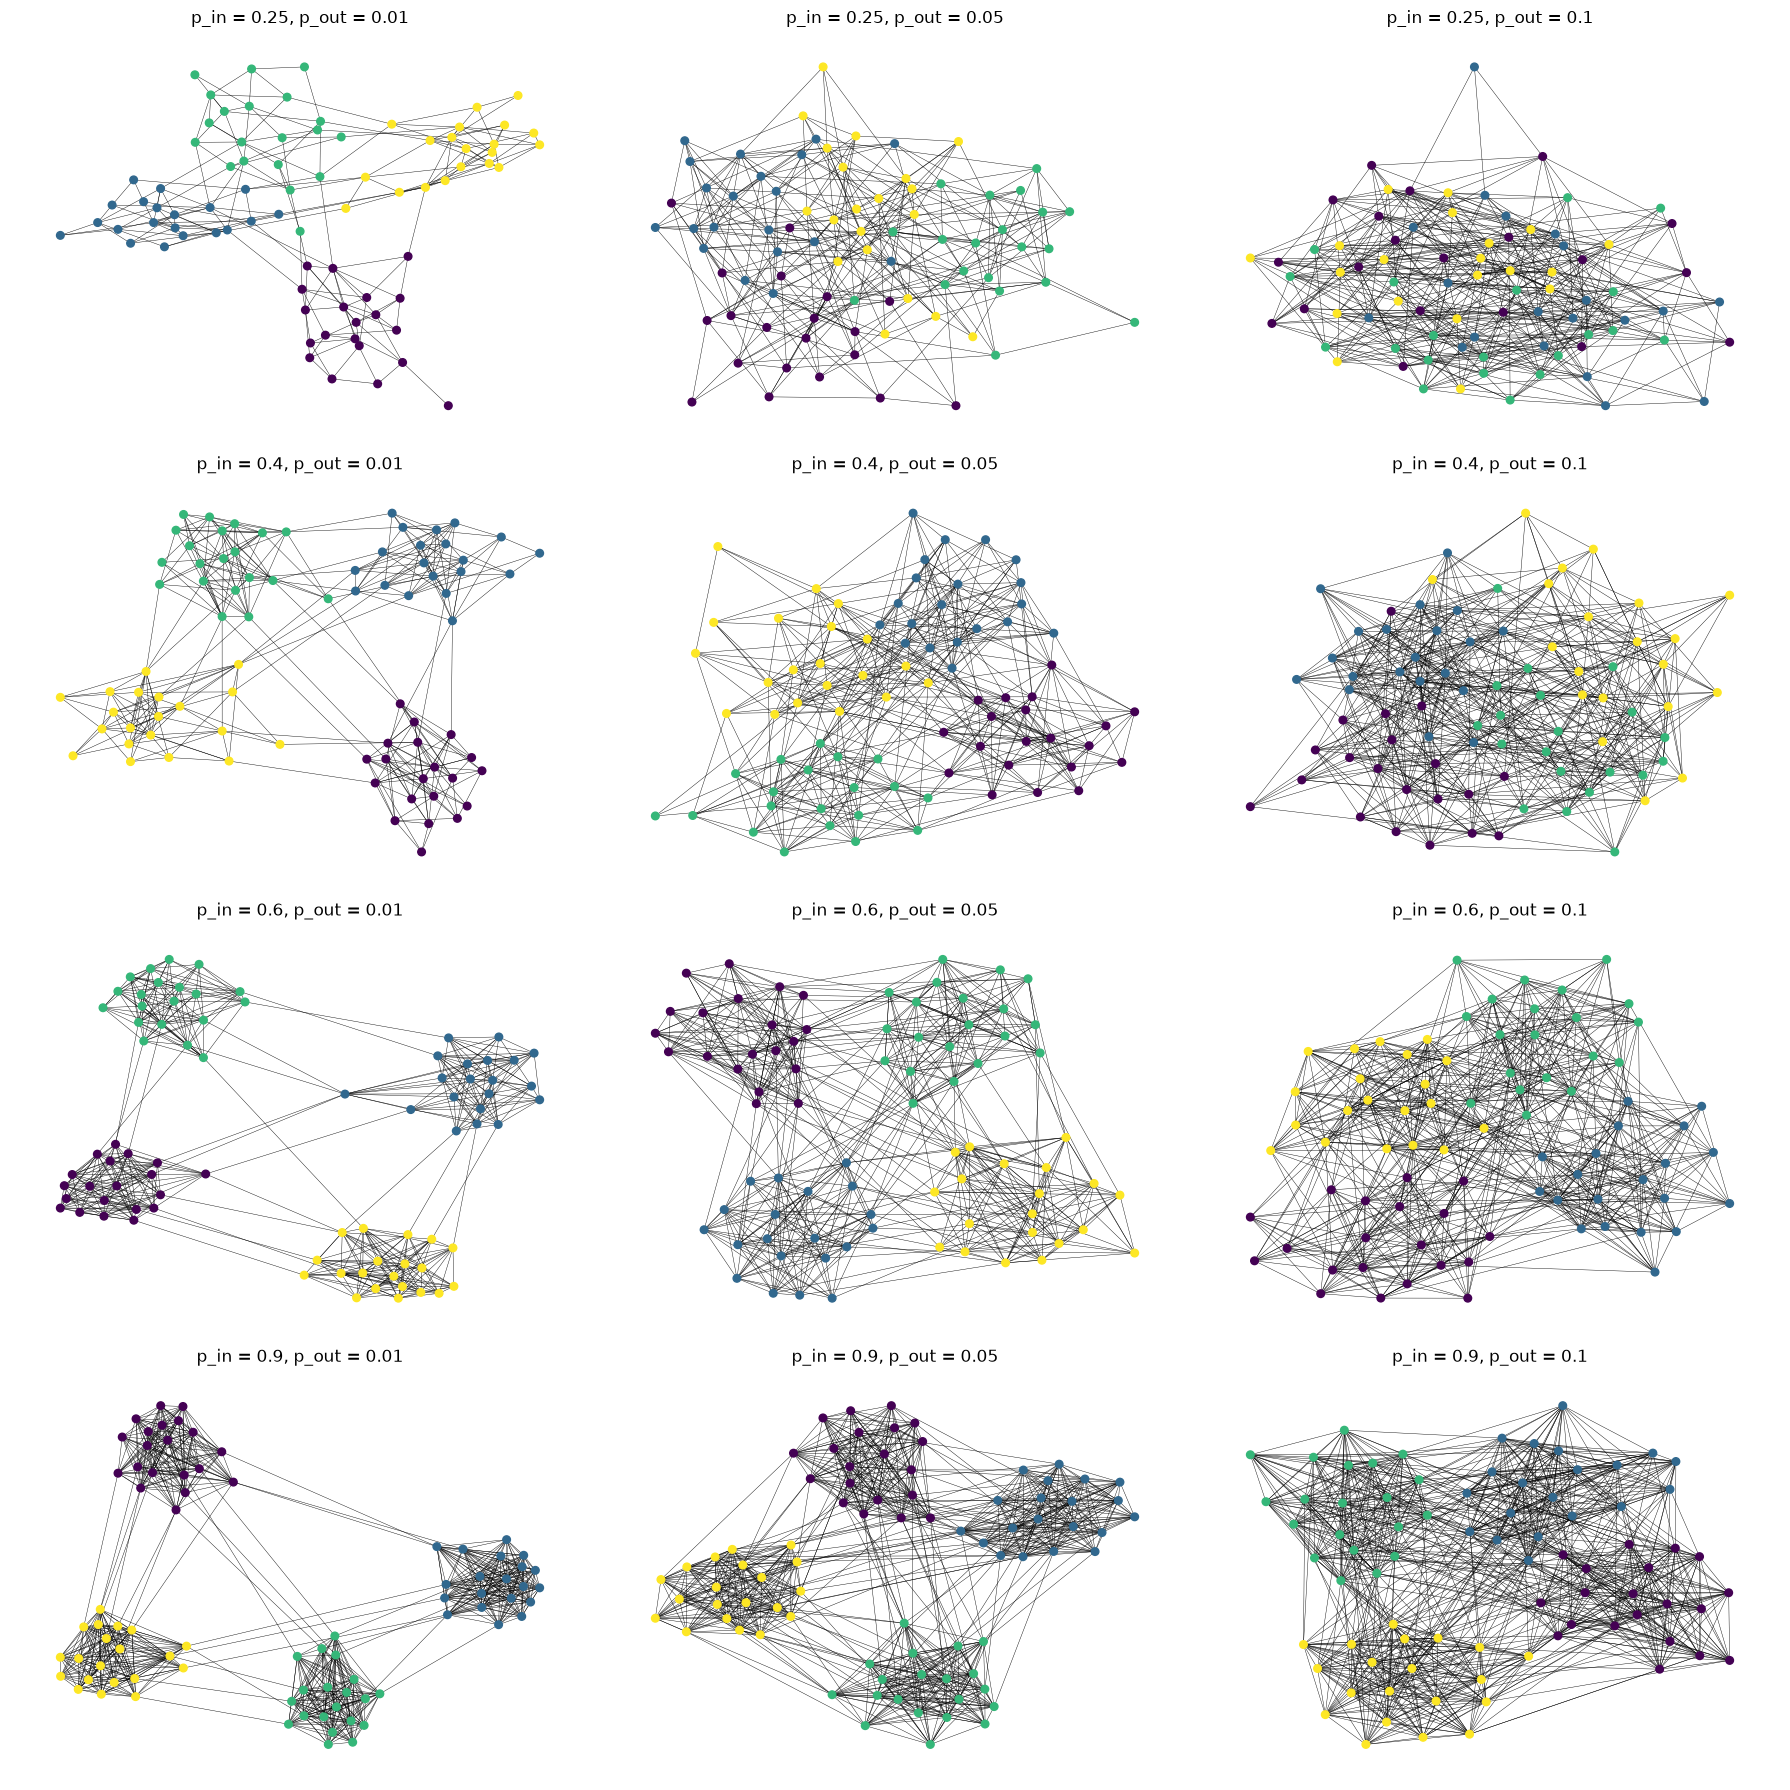

In [17]:
p_in_values = [0.25, 0.4, 0.6, 0.9]
p_out_values = [0.01, 0.05, 0.1]

fig, axes = plt.subplots(len(p_in_values), len(p_out_values), figsize=(18, 18))

for row in range(len(p_in_values)):
    for col in range(len(p_out_values)):
        p_in = p_in_values[row]
        p_out = p_out_values[col]
        p = [[p_in if i == j else p_out for j in range(4)] for i in range(4)]
        G = nx.stochastic_block_model([20] * 4, p)
        nx.draw(
            G,
            ax=axes[row, col],
            node_color=[i // 20 for i in G],
            node_size=30,
            width=0.3,
        )
        axes[row, col].set_title(f"p_in = {p_in}, p_out = {p_out}")
plt.tight_layout()
plt.show()

## 5.4 Draw a graph of the averaged coefficient of clustering of the WS network against its parameter p.


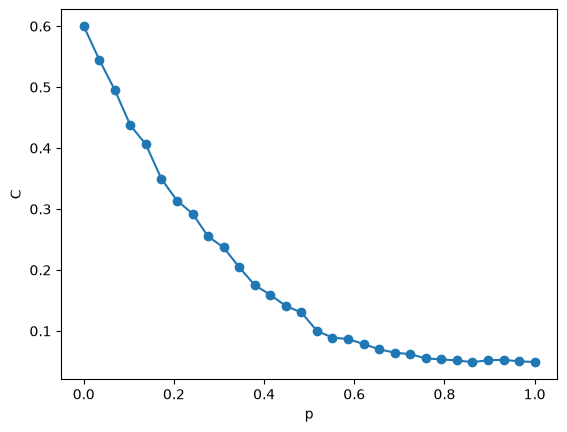

In [5]:
def watts_strogatz(n, k, p):
    assert 0 < k < n and k % 2 == 0 and 0 <= p <= 1

    G = []
    for u in range(n):
        G.append(set())

    edges = []
    for u in range(n):
        for distance in range(1, k // 2 + 1):
            v = (u + distance) % n
            edges.append((u, v))
            G[u].add(v)
            G[v].add(u)

    for u, v in edges:
        if np.random.random() < p:
            candidates = []
            for w in range(n):
                if w != u and w not in G[u]:
                    candidates.append(w)

            if candidates:
                w = int(np.random.choice(candidates))
                G[u].remove(v)
                G[v].remove(u)
                G[u].add(w)
                G[w].add(u)

    return G


def clustering(G):
    values = []
    for u in range(len(G)):
        neighbors = list(G[u])
        degree = len(neighbors)
        links = 0

        for i in range(degree):
            for j in range(i + 1, degree):
                if neighbors[j] in G[neighbors[i]]:
                    links += 1

        if degree > 1:
            values.append(2 * links / (degree * (degree - 1)))
        else:
            values.append(0)

    return np.mean(values)


p = np.linspace(0, 1, 30)
c = []
for x in p:
    results = []
    for _ in range(20):
        G = watts_strogatz(100, 6, x)
        results.append(clustering(G))
    c.append(np.mean(results))

plt.plot(p, c, marker="o")
plt.xlabel("p")
plt.ylabel("C")
plt.show()

## 5.6 Implement configuration model and test when the procedure converge.


In [6]:
from helpers import configuration_model, is_simple, success_rate, draw_multigraph

degrees: [1, 1, 1, 2, 2, 3]
is simple? (no self loops or multi-edges): False


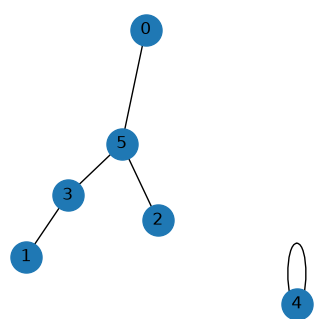

In [18]:
k = [1, 1, 1, 2, 2, 3]
res = configuration_model(k)
print("degrees:", k)
print("is simple? (no self loops or multi-edges):", is_simple(res))
G = draw_multigraph(res, len(k))

In [24]:
k = [1, 1, 1, 2, 2, 3]
tries = 1000
rate = success_rate(k, tries)
print(f"Success rate for simple graph with k={k} and {tries} tries: {rate}")

Success rate for simple graph with k=[1, 1, 1, 2, 2, 3] and 1000 tries: 0.365


degrees: [1, 1, 3, 3]
is simple? (no self loops or multi-edges): False


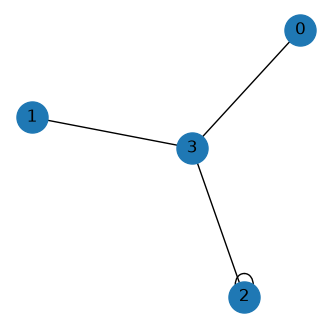

In [25]:
k = [1, 1, 3, 3]
res = configuration_model(k)
print("degrees:", k)
print("is simple? (no self loops or multi-edges):", is_simple(res))
G = draw_multigraph(res, len(k))

In [26]:
k = [1, 1, 3, 3]
tries = 1000
rate = success_rate(k, tries)
print(f"Success rate for simple graph with k={k} and {tries} tries: {rate}")

Success rate for simple graph with k=[1, 1, 3, 3] and 1000 tries: 0.0


degrees: [2, 2, 2]
is simple? (no self loops or multi edges): True


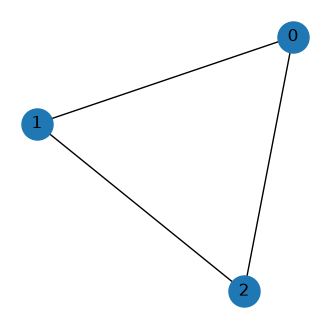

In [27]:
k = [2, 2, 2]
res = configuration_model(k)
print("degrees:", k)
print("is simple? (no self loops or multi edges):", is_simple(res))
G = draw_multigraph(res, len(k))

In [31]:
k = [2, 2, 2]
tries = 1000
rate = success_rate(k, tries)
print(f"Success rate for simple graph with k={k} and {tries} tries: {rate}")

Success rate for simple graph with k=[2, 2, 2] and 1000 tries: 0.525


degrees: [3 1 3 1 4 3 3 3 4 2 1 1 1 1 3 4 3 2 3 3 4 3 2 1 1 3 2 4 3 2]
is simple? (no self loops or multi-edges): False


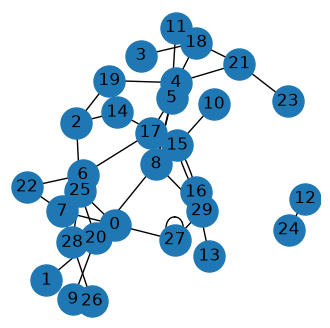

In [32]:
size = 30
k = np.random.randint(low=1, high=5, size=size)
if sum(k) % 2 != 0:
    k[np.random.randint(low=0, high=size)] += 1
res = configuration_model(k)
print("degrees:", k)
print("is simple? (no self loops or multi-edges):", is_simple(res))
G = draw_multigraph(res, len(k))

In [33]:
tries = 1000
rate = success_rate(k, tries)
print(f"Success rate for simple graph with k={k} and {tries} tries: {rate}")

Success rate for simple graph with k=[3 1 3 1 4 3 3 3 4 2 1 1 1 1 3 4 3 2 3 3 4 3 2 1 1 3 2 4 3 2] and 1000 tries: 0.155


### Convergence

$\langle k\rangle$ is the average degree: the mean number of edges per node.


In [15]:
def poisson_degrees(n, mean):
    k = []
    for i in range(n):
        k.append(int(np.random.poisson(mean)))
    if sum(k) % 2 != 0:
        k[np.random.randint(low=0, high=n)] += 1
    return k


def power_law_degrees(n, gamma, k_min=1):
    k = []
    for i in range(n):
        x = k_min * (1 - np.random.random()) ** (-1 / (gamma - 1))
        k.append(min(int(x), n - 1))
    if sum(k) % 2 != 0:
        k[np.random.randint(low=0, high=n)] += 1
    return k

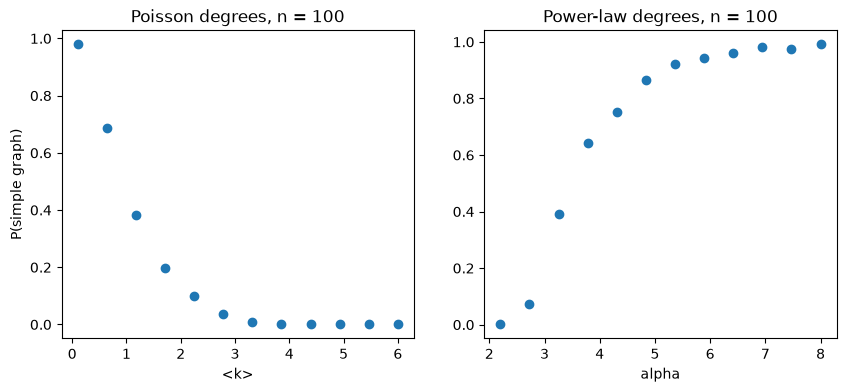

In [16]:
n = 100
samples = 10

# Poisson degrees: dependence on <k>
means = np.linspace(0.1, 6, 12)
sim_poisson = []
for m in means:
    rates = []
    for i in range(samples):
        k = poisson_degrees(n, m)
        rates.append(success_rate(k))
    sim_poisson.append(np.mean(rates))

# power-law degrees: dependence on alpha
alphas = np.linspace(2.2, 8, 12)
sim_power = []
for a in alphas:
    rates = []
    for i in range(samples):
        k = power_law_degrees(n, a)
        rates.append(success_rate(k))
    sim_power.append(np.mean(rates))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(means, sim_poisson, "o")
ax[0].set_xlabel("<k>")
ax[0].set_ylabel("P(simple graph)")
ax[0].set_title("Poisson degrees, n = 100")

ax[1].plot(alphas, sim_power, "o")
ax[1].set_xlabel("alpha")
ax[1].set_title("Power-law degrees, n = 100")
plt.show()